### Introduction

This tutorial shows how to use active learning to rapidly process a large dataset using a more computationally expensive method like docking, FEP, or 3D similarity calculations.  The code here is a scaled-down version of the code in our paper ["Optimizing active learning for free energy calculations"](https://www.sciencedirect.com/science/article/pii/S2667318522000204).  The code is fully functional.  I just removed a few of the options and benchmarks from our original work.  

### Setup

In [424]:
from operator import itemgetter

import numpy as np
import pandas as pd
import seaborn as sns
import sklearn.gaussian_process as gp
import useful_rdkit_utils as uru
from modAL.acquisition import BaseLearner
from modAL.models import BayesianOptimizer
from modAL.utils.data import modALinput
from modAL.acquisition import optimizer_PI
from rdkit import Chem
from sklearn.gaussian_process import GaussianProcessRegressor
from tqdm.auto import tqdm
from modAL.utils.selection import multi_argmax

In [425]:
import utils
from pathlib import Path 
from rdkit.Chem import Descriptors
import random 
from collections import Counter 
import sys 
sys.path.insert(1, '/Users/paulakramer/Documents/PHD/KinFragLib/kinase_active_learning/notebooks/recombination')
from recombination import recombine_ligands
from recombination import cli 
import frag_modifications

from rdkit.Contrib.SA_Score import sascorer


### Reading the data

In [426]:
# Path to library folder
HERE = Path(_dh[-1])
PATH_TO_LIB = HERE / '..' / 'data' / 'fragment_library_custom_filtered'

In [427]:
fragment_library = utils.read_fragment_library(PATH_TO_LIB)
fragment_library.keys()

dict_keys(['AP', 'FP', 'SE', 'GA', 'B1', 'B2'])

### Defining an Oracle

As with the classification example, we'll define an oracle that looks up values from a dataframe.  In practice, the oracle would perform some more expensive calculation like docking, FEP, or shape overlap. 

In [428]:
# calculates SA score
class Oracle: 
    def __init__(self, df):
        self.df = df
        self.subpockets = ['AP', 'FP', 'GA', 'SE']

    def get_values(self, mols): 
        # return [Descriptors.MolLogP(m) for m in mols]
        return [-sascorer.calculateScore(m)+11 for m in mols]
    
    def sample_one_pocket(self, num, pocket):
        sample_df = self.df[pocket].sample(num)
        return sample_df.fp.values, self.get_values(sample_df.ROMol_dummy), sample_df.smiles
    
    def sample(self, num): 
        pocket_sample = random.choices(self.subpockets, k=num)
        counter = Counter(pocket_sample).most_common()
        sample_df = {}
        for count in counter: 
            sample_df[count[0]] = self.df[count[0]].sample(count[1])
            for ind in sample_df[count[0]].index: 
                sample_df[count[0]].loc[ind].ROMol_original.SetProp("Index", str(ind))
        lib_path = HERE / '..' / 'data' / 'temp_library'
        utils.delete_folder(lib_path)
        
        utils.save_fragment_library_to_sdfs(lib_path, pd.concat(sample_df))
        com_path = Path(HERE  / '..'/ "data" / "temp" / "recombined")
        cli.process(com_path, lib_path, 'AP', 3)
        # writes recombined ligands to combinatorial_library.sdf 
        recombine_ligands.process(self.df, com_path)
        mols = utils.read_sdf(com_path / "combinatorial_library.sdf")
        # remap mol props from temp_lib to kinfraglib 
        return list(map(uru.mol2numpy_fp, mols)), [Chem.MolToSmiles(m) for m in mols], mols

    def fragment_sampling(self, num, mols, vals): 
        zipped = zip(mols, vals)
        zipped = sorted(zipped, key=lambda x: x[1], reverse=True) 
        ligands = []
        for mol, _ in zipped[:min(num, len(zipped))]: 
            frag_ids, bond_ids = utils.extract_meta(mol)
            res_tmp = []
            count = 0
            # query fragment exchange multiple times 
            # print("new ligand")
            while (len(res_tmp) < 50) and (count < 60): 
                # print("count: {count}")
                count += 1
                res = frag_modifications.fragment_modification(frag_ids, bond_ids, self.df, self.subpockets)
                if res is None: 
                    continue 
                if res[0] is None: 
                    continue
                if Chem.MolToSmiles(res[0]) not in res_tmp: 
                    res_tmp.append(Chem.MolToSmiles(res[0]))
                    ligands.append(res[0])
        return list(map(uru.mol2numpy_fp, ligands)), [Chem.MolToSmiles(m) for m in ligands], ligands
    

    def random_sampling(self, num, mols, vals): 
        zipped = list(zip(mols, vals))
        random.shuffle(zipped)
        ligands = []
        for mol, _ in zipped[:min(num, len(zipped))]: 
            frag_ids, bond_ids = utils.extract_meta(mol)
            res_tmp = []
            count = 0
            # query fragment exchange multiple times 
            while (len(res_tmp) < 50) and (count < 60): 
                # print("count: {count}")
                count += 1
                res = frag_modifications.fragment_modification(frag_ids, bond_ids, self.df, self.subpockets)
                if res is None: 
                    continue 
                if res[0] is None: 
                    continue
                if Chem.MolToSmiles(res[0]) not in res_tmp: 
                    res_tmp.append(Chem.MolToSmiles(res[0]))
                    ligands.append(res[0])
        return list(map(uru.mol2numpy_fp, ligands)), [Chem.MolToSmiles(m) for m in ligands], ligands

In [429]:
def sample_starting_distribution(X, smiles, mols, num): 
    zipped = list(zip(X, smiles, mols))
    random.shuffle(zipped)
    starting_dist = zipped[:num]
    starting_dist = list(zip(*starting_dist))
    return list(starting_dist[0]),  list(starting_dist[1]), list(starting_dist[2])

### Defining the Kernel Function for the Machine Learning Model

When we do active learning, we have to define a machine learning models that acts as a surrogate for the more expensive calculations.  In this case, we're going to use Gaussian Process Regression (GPR) to build our regression models.  To use GPR, we need to define a kernel function. Here we calculate a kernel based on the Tanimoto similarities of the molecules.

In [430]:
def calculate_similarity(a, b):
    # Tanimoto similarity a vs. b
    aa = np.sum(a, axis=1, keepdims=True)
    bb = np.sum(b, axis=1, keepdims=True)
    ab = np.matmul(a, b.T)
    return np.true_divide(ab, aa + bb.T - ab)


class TanimotoKernel(gp.kernels.NormalizedKernelMixin,
                     gp.kernels.StationaryKernelMixin, gp.kernels.Kernel):

    def __init__(self):
        pass

    def __call__(self, X, Y=None, eval_gradient=False):
        assert not eval_gradient
        if Y is None:
            Y = X
        return calculate_similarity(X, Y)

### Define Helper Functions for Active Learning

For the greedy search, we want to select the best scoring molecules, but we want to avoid selecting the same molecules multiple times. This function accepts a list of predictions and does the following.
- Sort by score
- Remove the molecules that were previously selected
- Return the top **n_to_choose**

In [431]:
def find_best_idx(predicted, used, num_to_choose):
    tmp_list = list(enumerate(predicted))
    tmp_list.sort(key=itemgetter(1), reverse=True)
    tmp_list = [x for x in tmp_list if x[0] not in used]
    tmp_list = [x[0] for x in tmp_list]
    return tmp_list[:num_to_choose]

In [432]:
def find_random_idx(predicted, used, num_to_choose):
    tmp_list = list(enumerate(predicted))
    random.shuffle(tmp_list)
    tmp_list = [x for x in tmp_list if x[0] not in used]
    tmp_list = [x[0] for x in tmp_list]
    return tmp_list[:num_to_choose]

Here are a couple of acquistion functions.  The first **greedy** simply selects the **n** top scoring molecules to be evaluated by the oracle.  The second **my_max_PI** maximizes the Probability of Improvement (PI) and uses uncertainty and the scores to balance exploration and exploitation.  The git repo associated with our paper ["Optimizing active learning for free energy calculations"](https://www.sciencedirect.com/science/article/pii/S2667318522000204) has examples of several other acquistion functions.  TLDR from our work, the acquistion function doesn't make a huge difference. 

In [433]:
def greedy(optimizer: BaseLearner, X: modALinput, n_instances=1, used=[]):
    res = optimizer.predict(X)
    best_idx = find_best_idx(res, used, n_instances)
    return best_idx, X[best_idx]

def my_max_PI(optimizer: BaseLearner, X: modALinput, tradeoff: float = 0,
           n_instances: int = 1, used = [], cycle = -1) -> np.ndarray:
    pi = optimizer_PI(optimizer, X, tradeoff=tradeoff)
    best_idx = find_best_idx(pi, used, n_instances)
    return best_idx, [X[i] for i in best_idx]

In [434]:
def greedy_base(optimizer: BaseLearner, X: modALinput, n_instances=1, used=[]):
    res = optimizer.predict(X)
    best_idx = find_random_idx(res, used, n_instances)
    return best_idx, X[best_idx]

def my_max_PI_base(optimizer: BaseLearner, X: modALinput, tradeoff: float = 0,
           n_instances: int = 1, used = [], cycle = -1) -> np.ndarray:
    pi = optimizer_PI(optimizer, X, tradeoff=tradeoff)
    best_idx = find_random_idx(pi, used, n_instances)
    return best_idx, [X[i] for i in best_idx]

### Create an Oracle

Create an oracle that will return values. This example oracle just looks up a value in a table.  In practice, you'd put code here to do a more expensive calculation.  The notebook **active_shape_search.ipynb** has a complete implementation of an oracle. 

In [435]:
oracle = Oracle(fragment_library)

In [436]:
list_1 = [1,2,3]
list_2 = [4, 5, 6]
list_zip = list(zip(list_1, list_2))
#list(zip(*list_zip))
list_zip

[(1, 4), (2, 5), (3, 6)]

### Run Active Learning

This is the main active learning loop.

In [437]:
# number of molecules to select at each active learning cycle
n_instances = 50
# number of active learning cycles to run
n_cycles = 6
start_instances = 100 

# define the acquistion function, to change to greedy just change the line below
query_strategy = my_max_PI
# select an initial random cycle
X_initial, sample_smi_init, sample_mols_init = oracle.sample(n_instances)
X_initial, sample_smi_init, sample_mols_init = sample_starting_distribution(X_initial, sample_smi_init, sample_mols_init, start_instances)
vals_init = oracle.get_values(sample_mols_init)
# instantiate the optimizer with an estimator, training data, and an acquistion function
optimizer = BayesianOptimizer(estimator=GaussianProcessRegressor(kernel=TanimotoKernel()),
                              X_training=np.stack(X_initial), y_training=vals_init,
                              query_strategy=query_strategy)
# initialize a list of scores
val_list = vals_init.copy()
# keep track of which molecules we've sampled

used = sample_smi_init.copy()
used_mols = sample_mols_init.copy()
# the active learning loop
loop_indices = [len(used)]
for i in tqdm(range(0, n_cycles)):
    fps, sample_smi, sample_mols = oracle.fragment_sampling(50, used_mols, val_list)
    # ask the optimizer for the next set of molecules
    used_idx = utils.check_used(sample_smi, used)
    query_ind, query_desc = optimizer.query(fps, n_instances=50, used=used_idx)
    # get values from the oracle, in practice, this is where we would do the more expensive calculations
    vals = oracle.get_values([sample_mols[i] for i in query_ind])
    # add the returned values to val_list
    val_list += vals
    # keep track of the molecules we've used
    used += [sample_smi[i] for i in query_ind]
    used_mols += [sample_mols[i] for i in query_ind]
    loop_indices.append(len(vals))
    # update the optimizer with the new values
    optimizer.teach(query_desc, vals)

Subpocket B1 not available.
Subpocket B2 not available.
Number of fragments:  50
Write 656 results to file 0
Number of resulting ligands:  656
Number of ligands including duplicates:  1217
Overall number of fragments in queue:  129
Time:  680179.1855587959


[12:52:43] Initializing MetalDisconnector
[12:52:43] Running MetalDisconnector
[12:52:43] Initializing Normalizer
[12:52:43] Running Normalizer
[12:52:43] Running Uncharger
[12:52:43] Initializing MetalDisconnector
[12:52:43] Running MetalDisconnector
[12:52:43] Initializing Normalizer
[12:52:43] Running Normalizer
[12:52:43] Running Uncharger
[12:52:43] Initializing MetalDisconnector
[12:52:43] Running MetalDisconnector
[12:52:43] Initializing Normalizer
[12:52:43] Running Normalizer
[12:52:43] Running Uncharger
[12:52:43] Initializing MetalDisconnector
[12:52:43] Running MetalDisconnector
[12:52:43] Initializing Normalizer
[12:52:43] Running Normalizer
[12:52:43] Running Uncharger
[12:52:43] Initializing MetalDisconnector
[12:52:43] Running MetalDisconnector
[12:52:43] Initializing Normalizer
[12:52:43] Running Normalizer
[12:52:43] Running Uncharger
[12:52:43] Initializing MetalDisconnector
[12:52:43] Running MetalDisconnector
[12:52:43] Initializing Normalizer
[12:52:43] Running No

Number of recombined ligands from all iterations: 656


  0%|          | 0/6 [00:00<?, ?it/s]

#### Random baselines

In [438]:
# define the acquistion function, to change to greedy just change the line below
query_strategy = my_max_PI

# instantiate the optimizer with an estimator, training data, and an acquistion function
optimizer = BayesianOptimizer(estimator=GaussianProcessRegressor(kernel=TanimotoKernel()),
                              X_training=np.stack(X_initial), y_training=vals_init,
                              query_strategy=query_strategy)
# initialize a list of scores
val_list_rand = vals_init.copy()
# keep track of which molecules we've sampled
used_rand = sample_smi_init.copy()
used_mols_rand = sample_mols_init.copy()
# the active learning loop
loop_indices_rand = [len(used_rand)]
for i in tqdm(range(0, n_cycles)):
    fps, sample_smi, sample_mols = oracle.random_sampling(50, used_mols_rand, val_list_rand)
    # ask the optimizer for the next set of molecules
    used_idx_rand = utils.check_used(sample_smi, used_rand)
    query_ind, query_desc = optimizer.query(fps, n_instances=50, used=used_idx_rand)
    # get values from the oracle, in practice, this is where we would do the more expensive calculations
    vals = oracle.get_values([sample_mols[i] for i in query_ind])
    # add the returned values to val_list
    val_list_rand += vals
    # keep track of the molecules we've used
    used_rand += [sample_smi[i] for i in query_ind]
    used_mols_rand += [sample_mols[i] for i in query_ind]
    loop_indices_rand.append(len(vals))
    # update the optimizer with the new values
    optimizer.teach(query_desc, vals)

  0%|          | 0/6 [00:00<?, ?it/s]

In [439]:
# define the acquistion function, to change to greedy just change the line below
query_strategy = my_max_PI_base

# instantiate the optimizer with an estimator, training data, and an acquistion function
optimizer = BayesianOptimizer(estimator=GaussianProcessRegressor(kernel=TanimotoKernel()),
                              X_training=np.stack(X_initial), y_training=vals_init,
                              query_strategy=query_strategy)
# initialize a list of scores
val_list_rand_1 = vals_init.copy()
# keep track of which molecules we've sampled
used_rand_1 = sample_smi_init.copy()
used_mols_rand_1 = sample_mols_init.copy()
# the active learning loop
loop_indices_rand_1 = [len(used_rand_1)]
for i in tqdm(range(0, n_cycles)):
    fps, sample_smi, sample_mols = oracle.random_sampling(50, used_mols_rand_1, val_list_rand_1)
    # ask the optimizer for the next set of molecules
    used_idx_rand_1 = utils.check_used(sample_smi, used_rand_1)
    query_ind, query_desc = optimizer.query(fps, n_instances=50, used=used_idx_rand_1)
    # get values from the oracle, in practice, this is where we would do the more expensive calculations
    vals = oracle.get_values([sample_mols[i] for i in query_ind])
    # add the returned values to val_list
    val_list_rand_1 += vals
    # keep track of the molecules we've used
    used_rand_1 += [sample_smi[i] for i in query_ind]
    used_mols_rand_1 += [sample_mols[i] for i in query_ind]
    loop_indices_rand_1.append(len(vals))
    # update the optimizer with the new values
    optimizer.teach(query_desc, vals)

  0%|          | 0/6 [00:00<?, ?it/s]

### Analyze Active Learning Results

Let's look at how the scores were distributed across the active learning cycles. First we need to put the data in a dataframe.

In [440]:
res_list = []
cur_ind = 0
for i, v in enumerate(loop_indices): 
    res_list += [(i, x) for x in val_list[cur_ind:cur_ind+v]]
    cur_ind += v
res_list
res_df = pd.DataFrame(res_list, columns=["cycle", "SA score"])
res_df['SMILES'] = used
res_df = res_df.drop_duplicates(subset='SMILES', keep="last")
res_df

,cycle,SA score,SMILES
0,0,9.099521,O=C(Nc1cc2ccccc2o1)c1ccc(F)cc1
1,0,8.188301,Cc1csc2c(-c3nnc4ccccn34)nc(NCCc3cccnc3)nc12
2,0,8.792878,O=C(NCc1cccc(C2CCNCC2)c1)c1ccc(-c2ccc(O)cc2Cl)cc1
3,0,8.664364,NC(=O)c1ccc(-c2nnc3ccc(-c4ccc(O)cc4O)cn23)cc1
4,0,8.525495,COc1cc(N2CCCCC2)ccc1-c1nnc2ccc(-c3ccc(O)cc3Cl)...
...,...,...,...
393,6,9.570950,O=C(NCc1cccc(O)c1)c1ccccc1
394,6,9.337655,COc1cc(NC(=O)c2ccncc2)ccc1Cl
395,6,9.434609,CC(=O)c1cccc(-c2cccc(NC(=O)c3ccccc3)c2)c1
397,6,9.410923,COc1ccc(NC(=O)c2ccncc2)cc1OC


In [441]:
res_list_rand = []
cur_ind = 0
for i, v in enumerate(loop_indices_rand): 
    res_list_rand += [(i, x) for x in val_list_rand[cur_ind:cur_ind+v]]
    cur_ind += v
res_list_rand
res_rand_df = pd.DataFrame(res_list_rand, columns=["cycle", "SA score"])
res_rand_df['SMILES'] = used_rand
res_rand_df = res_rand_df.drop_duplicates(subset='SMILES', keep="last")
res_rand_df

,cycle,SA score,SMILES
0,0,9.099521,O=C(Nc1cc2ccccc2o1)c1ccc(F)cc1
1,0,8.188301,Cc1csc2c(-c3nnc4ccccn34)nc(NCCc3cccnc3)nc12
2,0,8.792878,O=C(NCc1cccc(C2CCNCC2)c1)c1ccc(-c2ccc(O)cc2Cl)cc1
3,0,8.664364,NC(=O)c1ccc(-c2nnc3ccc(-c4ccc(O)cc4O)cn23)cc1
4,0,8.525495,COc1cc(N2CCCCC2)ccc1-c1nnc2ccc(-c3ccc(O)cc3Cl)...
...,...,...,...
394,6,8.440844,COc1cnc(-c2n[nH]c3cccc(-c4ccc(C(=O)NCc5ccc(F)c...
396,6,8.886930,Cn1ncc2cc(CNC(=O)c3ccc(OCc4cccc5ccccc45)cc3)ccc21
397,6,9.261300,CCc1cccc(NC(=O)c2ccc(F)cc2)n1
398,6,9.125942,O=C(NCc1ccc(N2CCOCC2)cc1)c1ccc(-c2ccc(O)cc2)cc1


In [442]:
res_list_rand_1 = []
cur_ind = 0
for i, v in enumerate(loop_indices_rand_1): 
    res_list_rand_1 += [(i, x) for x in val_list_rand_1[cur_ind:cur_ind+v]]
    cur_ind += v
res_list_rand_1
res_rand_1_df = pd.DataFrame(res_list_rand_1, columns=["cycle", "SA score"])
res_rand_1_df['SMILES'] = used_rand_1
res_rand_1_df = res_rand_1_df.drop_duplicates(subset='SMILES', keep="last")
res_rand_1_df

,cycle,SA score,SMILES
0,0,9.099521,O=C(Nc1cc2ccccc2o1)c1ccc(F)cc1
1,0,8.188301,Cc1csc2c(-c3nnc4ccccn34)nc(NCCc3cccnc3)nc12
2,0,8.792878,O=C(NCc1cccc(C2CCNCC2)c1)c1ccc(-c2ccc(O)cc2Cl)cc1
3,0,8.664364,NC(=O)c1ccc(-c2nnc3ccc(-c4ccc(O)cc4O)cn23)cc1
4,0,8.525495,COc1cc(N2CCCCC2)ccc1-c1nnc2ccc(-c3ccc(O)cc3Cl)...
...,...,...,...
395,6,8.374759,COc1cc(C(N)=O)ccc1Nc1n[nH]c2cc(-c3c(C)ccc4[nH]...
396,6,8.443681,O=C(NC1CC1)c1ccc(-c2ccc3c(Nc4cccc(-n5nccn5)c4)...
397,6,7.877060,CCn1cc(-c2cnc3c(-c4c(-c5ncc(OC)cn5)n[nH]c4-c4c...
398,6,8.266106,Cc1nc(C)c(-c2cnc3c(-c4ccc(O)cc4Cl)cnn3c2)s1


In [443]:
res_df = res_df.assign(strategy="Optimized")
res_rand_df = res_rand_df.assign(strategy="Random mod/opt query")
res_rand_1_df = res_rand_1_df.assign(strategy="Random")
merged_df = pd.concat([res_df, res_rand_df, res_rand_1_df])
merged_df

,cycle,SA score,SMILES,strategy
0,0,9.099521,O=C(Nc1cc2ccccc2o1)c1ccc(F)cc1,Optimized
1,0,8.188301,Cc1csc2c(-c3nnc4ccccn34)nc(NCCc3cccnc3)nc12,Optimized
2,0,8.792878,O=C(NCc1cccc(C2CCNCC2)c1)c1ccc(-c2ccc(O)cc2Cl)cc1,Optimized
3,0,8.664364,NC(=O)c1ccc(-c2nnc3ccc(-c4ccc(O)cc4O)cn23)cc1,Optimized
4,0,8.525495,COc1cc(N2CCCCC2)ccc1-c1nnc2ccc(-c3ccc(O)cc3Cl)...,Optimized
...,...,...,...,...
395,6,8.374759,COc1cc(C(N)=O)ccc1Nc1n[nH]c2cc(-c3c(C)ccc4[nH]...,Random
396,6,8.443681,O=C(NC1CC1)c1ccc(-c2ccc3c(Nc4cccc(-n5nccn5)c4)...,Random
397,6,7.877060,CCn1cc(-c2cnc3c(-c4c(-c5ncc(OC)cn5)n[nH]c4-c4c...,Random
398,6,8.266106,Cc1nc(C)c(-c2cnc3c(-c4ccc(O)cc4Cl)cnn3c2)s1,Random


Plot the scores of the molecules selected in each active learning round.  Remember that the first active learning cycle was randomly selected. 

#### SA score 

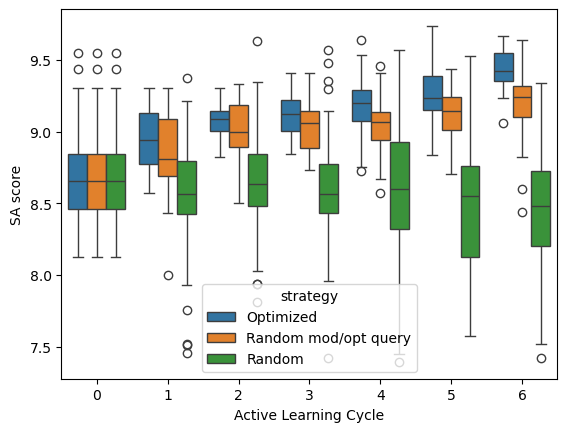

In [444]:
# maximize flipped SA score -> easy to synthesize, 50 modifications per ligand, sampled initial distribution
ax = sns.boxplot(x="cycle", y="SA score", data=merged_df, hue='strategy')
ax.set_xlabel("Active Learning Cycle");

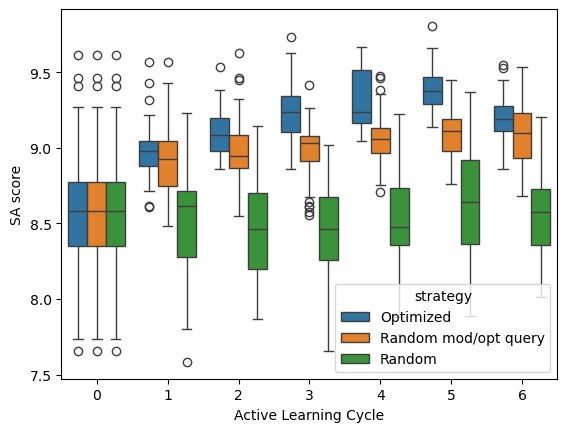

In [376]:
# maximize flipped SA score -> easy to synthesize, 50 modifications per ligand 
ax = sns.boxplot(x="cycle", y="SA score", data=merged_df, hue='strategy')
ax.set_xlabel("Active Learning Cycle");

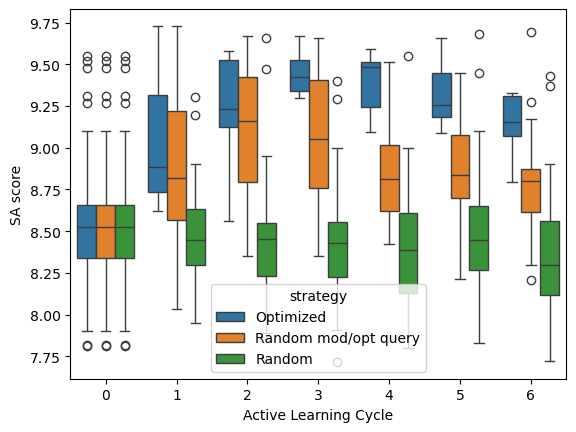

In [362]:
# maximize flipped SA score -> easy to synthesize, 30 modifications per ligand 
ax = sns.boxplot(x="cycle", y="SA score", data=merged_df, hue='strategy')
ax.set_xlabel("Active Learning Cycle");

Now let's plot the distributions for the top 100 molecules from the input data vs the top 100 found using active learning.

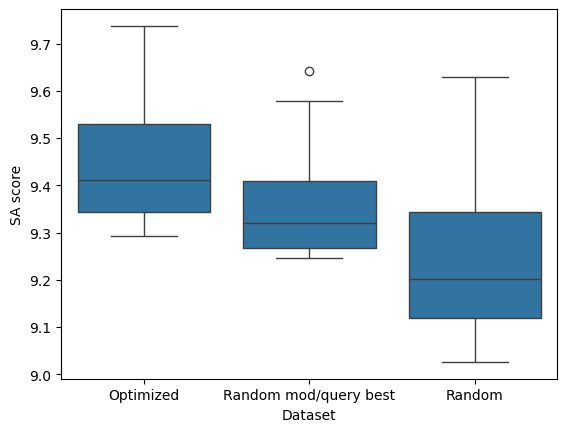

In [445]:
res_top_100 = res_df.sort_values("SA score",ascending=False).head(50).copy()
res_top_100['Dataset'] = 'Optimized'
rand_top_100 = res_rand_df.sort_values("SA score",ascending=False).head(50).copy()
rand_top_100['Dataset'] = 'Random mod/query best'
rand_1_top_100 = res_rand_1_df.sort_values("SA score",ascending=False).head(50).copy()
rand_1_top_100['Dataset'] = 'Random'
# Make a boxplot comparing the scores of the top 100 molecules
ax = sns.boxplot(x="Dataset", y="SA score", data=pd.concat([res_top_100,rand_top_100, rand_1_top_100]));
ax.set_ylabel("SA score");

We can also compare the scores of the molecules selected by active learning with scores from randomly selected molecules. 

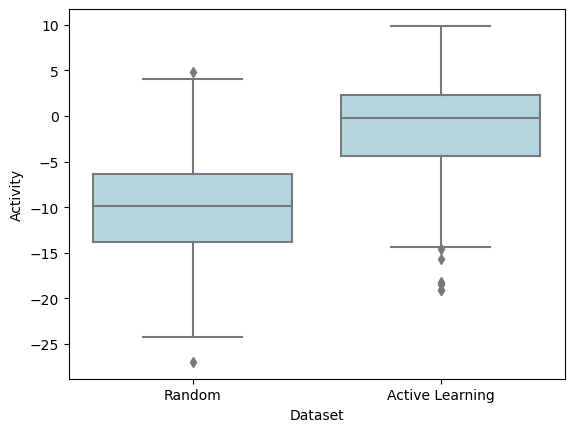

In [ ]:
# Take a random sample from the input data that is the same size as the dataframe with the selected molecules
random_df = df.sample(len(res_df)).copy()
random_df['Dataset'] = 'Random'
# Label the active learning data
res_df['Dataset'] = 'Active Learning'
ax = sns.boxplot(x="Dataset", y="Activity", data=pd.concat([random_df,res_df]),color="lightblue");
ax.set_ylabel("Activity");